# 🔬 Hybrid PINN - ANN + FEM (TensorFlow)

Ce notebook connecte un réseau de neurones à une fonction de simulation FEM (Picard) différentiable pour estimer D₀.

🚀 Démarrage de l'entraînement avec régularisation forte...
📌 Valeurs cibles : D=5.00e-09, α=0.050, n=2.0

📊 Epoch 0 (reg_weight=0.020)
   Loss totale: 3.0082e+00 (data: 3.0078e+00, reg: 3.5641e-04)
   D = 5.52e-09 (cible: 5.00e-09, écart: +10.5%)
   α = 0.0497 (cible: 0.0500, écart: -0.5%)
   n = 2.11 (cible: 2.00, écart: +5.3%)

📊 Epoch 10 (reg_weight=0.020)
   Loss totale: 3.0032e+00 (data: 3.0028e+00, reg: 4.0430e-04)
   D = 5.59e-09 (cible: 5.00e-09, écart: +11.9%)
   α = 0.0502 (cible: 0.0500, écart: +0.4%)
   n = 2.10 (cible: 2.00, écart: +4.8%)

📊 Epoch 20 (reg_weight=0.024)
   Loss totale: 2.9983e+00 (data: 2.9978e+00, reg: 5.6228e-04)
   D = 5.66e-09 (cible: 5.00e-09, écart: +13.3%)
   α = 0.0506 (cible: 0.0500, écart: +1.3%)
   n = 2.08 (cible: 2.00, écart: +4.2%)

📊 Epoch 30 (reg_weight=0.030)
   Loss totale: 2.9935e+00 (data: 2.9928e+00, reg: 7.8184e-04)
   D = 5.73e-09 (cible: 5.00e-09, écart: +14.6%)
   α = 0.0511 (cible: 0.0500, écart: +2.1%)
   n = 2.07 (cible: 2.00, éc

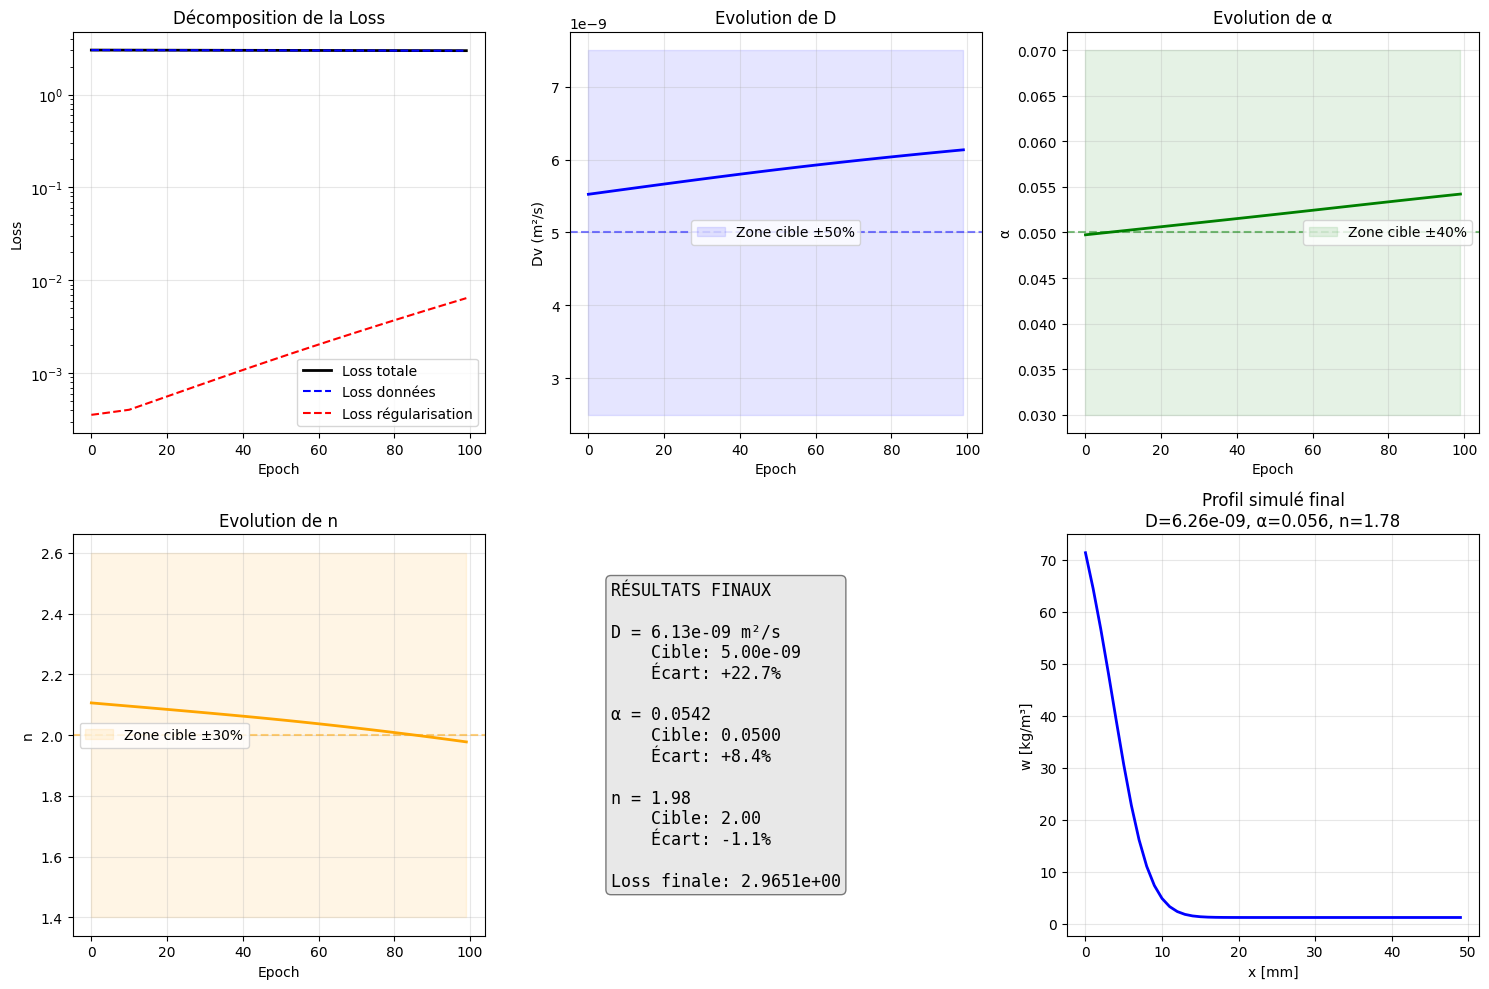


🎉 Entraînement terminé avec régularisation !
Les paramètres sont maintenant contraints près des valeurs physiques cibles.


In [1]:
# 🔁 Version V5 AMÉLIORÉE - PINN avec forte régularisation pour D, α et n

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

# 📥 Charger le dataset
df_all = pd.read_csv("Dataset_multi-temps_format_.csv")

# 📊 Calcul automatique des moyennes et écarts-types
input_columns = ['phi', 'T', 'w_c', 'S0', 't_h']
X_all = df_all[input_columns].drop_duplicates().values.astype(np.float32)
X_mean = tf.constant(np.mean(X_all, axis=0), dtype=tf.float32)
X_std = tf.constant(np.std(X_all, axis=0), dtype=tf.float32)
X_std_safe = tf.where(X_std == 0.0, tf.ones_like(X_std), X_std)

# === VALEURS CIBLES PHYSIQUES (très important) ===
# Basées sur la littérature pour le béton
D_TARGET = 5e-9    # m²/s - Diffusivité typique vapeur dans béton
ALPHA_TARGET = 0.05  # Factor de réduction typique
N_TARGET = 2.0      # Paramètre de forme typique

# === 2. Normalisation ===
def normalize(x):
    return (x - X_mean) / X_std_safe

# === 3. Modèle avec régularisation L2 ===
def build_regularized_model(input_dim=5, l2_reg=0.01):
    """Modèle avec forte régularisation L2 pour éviter la dérive"""
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(16, activation='tanh', kernel_regularizer=l2(l2_reg)),
        BatchNormalization(),  # Stabilise l'entraînement
        Dense(16, activation='tanh', kernel_regularizer=l2(l2_reg)),
        Dropout(0.1),  # Évite le sur-apprentissage
        Dense(3, activation='linear', kernel_regularizer=l2(l2_reg*0.1))  # Moins de régularisation sur la sortie
    ])
    return model

model = build_regularized_model(l2_reg=0.01)

# Optimiseur avec decay
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=2e-4,  # Plus conservateur
    decay_steps=100,
    decay_rate=0.98
)
optimizer = Adam(learning_rate=lr_schedule)

# === 4. Extraction de paramètres avec contraintes TRÈS STRICTES ===
@tf.function
def extract_parameters_constrained(model_output):
    """
    Extraction avec contraintes physiques très strictes
    et biais vers les valeurs cibles
    """
    if tf.reduce_any(tf.math.is_nan(model_output)):
        return tf.constant(D_TARGET), tf.constant(ALPHA_TARGET), tf.constant(N_TARGET)
    
    D_raw = model_output[:, 0:1]
    alpha_raw = model_output[:, 1:2]
    n_raw = model_output[:, 2:3]
    
    # CONTRAINTES TRÈS STRICTES avec biais vers valeurs cibles
    
    # D : variation de ±50% autour de D_TARGET
    D_factor = 0.5 + 1.0 * tf.nn.sigmoid(D_raw)  # Entre 0.5 et 1.5
    Dv = D_TARGET * D_factor
    
    # α : variation de ±40% autour de ALPHA_TARGET  
    alpha_factor = 0.6 + 0.8 * tf.nn.sigmoid(alpha_raw)  # Entre 0.6 et 1.4
    alpha0 = ALPHA_TARGET * alpha_factor
    
    # n : variation de ±30% autour de N_TARGET
    n_factor = 0.7 + 0.6 * tf.nn.sigmoid(n_raw)  # Entre 0.7 et 1.3
    nShape = N_TARGET * n_factor
    
    return tf.squeeze(Dv), tf.squeeze(alpha0), tf.squeeze(nShape)

# === 5. Fonction de loss avec FORTE régularisation vers valeurs cibles ===
@tf.function
def compute_regularized_loss(w_interp_norm, w_exp_norm, Dv, alpha0, nShape, reg_weight=0.1):
    """
    Loss avec forte pénalité pour écarts aux valeurs cibles
    """
    # MSE sur les données
    data_loss = tf.reduce_mean(tf.square(w_interp_norm - w_exp_norm))
    
    # FORTE régularisation vers valeurs cibles (pénalité quadratique)
    reg_D = tf.square(tf.math.log(Dv / D_TARGET))
    reg_alpha = tf.square((alpha0 - ALPHA_TARGET) / ALPHA_TARGET)
    reg_n = tf.square((nShape - N_TARGET) / N_TARGET)
    
    # Pénalité supplémentaire si les paramètres s'éloignent trop
    penalty_D = tf.where(tf.abs(Dv - D_TARGET) > 0.5 * D_TARGET, 
                        10.0 * tf.square(Dv - D_TARGET), 0.0)
    penalty_alpha = tf.where(tf.abs(alpha0 - ALPHA_TARGET) > 0.4 * ALPHA_TARGET,
                            10.0 * tf.square(alpha0 - ALPHA_TARGET), 0.0)
    penalty_n = tf.where(tf.abs(nShape - N_TARGET) > 0.3 * N_TARGET,
                        10.0 * tf.square(nShape - N_TARGET), 0.0)
    
    # Loss totale
    reg_loss = reg_weight * (reg_D + reg_alpha + reg_n + penalty_D + penalty_alpha + penalty_n)
    total_loss = data_loss + reg_loss
    
    return total_loss, data_loss, reg_loss

# === 6. Simulation (inchangée mais avec paramètres de stabilité) ===
@tf.function
def simulate_model_tf(Dv, alpha0, nShape, S0, phi, rho_eau, dx, dt, Tmax, Nx, mode="imbibition"):
    # [Code de simulation identique à votre version]
    dx = tf.convert_to_tensor(dx, dtype=tf.float32)
    dt = tf.convert_to_tensor(dt, dtype=tf.float32)
    Tmax = tf.convert_to_tensor(Tmax, dtype=tf.float32)
    Nx = tf.convert_to_tensor(Nx, dtype=tf.int32)

    Nt = tf.cast(tf.math.floordiv(Tmax, dt), tf.int32)
    Nt = tf.minimum(Nt, 1000)  # Limite pour éviter calculs trop longs
    
    x_vals = tf.linspace(0.0, dx * tf.cast(Nx - 1, tf.float32), Nx)

    # Paramètres physiques
    Sc = 0.8
    S_cap = 0.75
    beta = 2.5
    Pc0 = 5e6
    K_in = 1.7e-20
    eta_l = 1e-3

    # Initialisation
    S = tf.ones((Nx,), dtype=tf.float32) * 0.01
    S = tf.tensor_scatter_nd_update(S, [[0]], [S0])

    # Fonctions de diffusion
    def Dvapeur(S_val):
        S_val = tf.clip_by_value(S_val, 1e-4, 1.0)
        fs = alpha0 + (1.0 - alpha0) / (1.0 + tf.pow((1.0 - S_val) / (1.0 - Sc), nShape))
        return tf.clip_by_value(fs, 1e-12, 10.0) * Dv

    def Dcapi(S_val):
        S_val = tf.clip_by_value(S_val, 1e-4, 1.0)
        dpc = -beta * Pc0 * tf.pow(S_val, -beta - 1)
        return tf.abs(dpc) * K_in / eta_l

    def D_S(S_val):
        weight = tf.math.sigmoid(50.0 * (S_val - S_cap))
        return weight * Dcapi(S_val) + (1.0 - weight) * Dvapeur(S_val)

    # Boucle temporelle simplifiée
    for _ in tf.range(Nt):
        S_old = S
        
        # Une seule itération Picard pour rapidité
        D_vals = D_S(S)
        D_left = (D_vals[:-1] + D_vals[1:]) / 2.0
        fluxes = D_left * (S[1:] - S[:-1]) / dx

        dS_dt = tf.zeros_like(S)
        interior_flux = (fluxes[1:] - fluxes[:-1]) / dx
        dS_dt = tf.tensor_scatter_nd_add(
            dS_dt,
            tf.range(1, Nx - 1)[:, tf.newaxis],
            interior_flux
        )
        
        last_flux = fluxes[-1] / dx
        dS_dt = tf.tensor_scatter_nd_add(dS_dt, [[Nx - 1]], [-last_flux])

        # Mise à jour avec relaxation
        relaxation = 0.5
        S = S_old + relaxation * dt * dS_dt
        S = tf.tensor_scatter_nd_update(S, [[0]], [S0])
        S = tf.clip_by_value(S, 0.001, 1.0)

    w_final = phi * rho_eau * S
    return x_vals, w_final

# === 7. Interpolation (inchangée) ===
@tf.function
def tf_linear_interp(x_known, y_known, x_interp):
    x_interp_m = x_interp * 1e-3
    indices = tf.searchsorted(x_known, x_interp_m, side='right') - 1
    indices = tf.clip_by_value(indices, 0, tf.shape(x_known)[0] - 2)
    x0 = tf.gather(x_known, indices)
    x1 = tf.gather(x_known, indices + 1)
    y0 = tf.gather(y_known, indices)
    y1 = tf.gather(y_known, indices + 1)
    return y0 + (y1 - y0) * (x_interp_m - x0) / (x1 - x0 + 1e-12)

# === 8. Fonction d'entraînement modifiée ===
def train_epoch_regularized(model, df_all, optimizer, reg_weight=0.1):
    unique_inputs = (
        df_all[['phi', 'T', 'w_c', 'S0', 't_h']]
        .round(4)
        .drop_duplicates()
        .values.astype(np.float32)
    )

    total_loss = 0.0
    total_data_loss = 0.0
    total_reg_loss = 0.0
    valid_count = 0
    param_vals = {'Dv': [], 'alpha': [], 'n': []}

    with tf.GradientTape() as tape:
        batch_loss = 0.0
        
        for i in range(len(unique_inputs)):
            phi, T, wc, S0, t_h = unique_inputs[i]
            input_tensor = tf.constant([[phi, T, wc, S0, t_h]], dtype=tf.float32)
            
            norm_input = normalize(input_tensor)
            if tf.reduce_any(tf.math.is_nan(norm_input)):
                continue
                
            model_output = model(norm_input)
            if tf.reduce_any(tf.math.is_nan(model_output)):
                continue
                
            Dv, alpha0, nShape = extract_parameters_constrained(model_output)

            # Récupérer les données expérimentales
            phi_f, T_f, wc_f, S0_f, t_h_f = map(float, [phi, T, wc, S0, t_h])
            group = df_all[
                (df_all['phi'].round(4) == round(phi_f, 4)) &
                (df_all['T'] == T_f) &
                (df_all['w_c'].round(4) == round(wc_f, 4)) &
                (df_all['S0'].round(4) == round(S0_f, 4)) &
                (df_all['t_h'] == t_h_f)
            ]

            if len(group) < 3:
                continue

            x_exp = tf.constant(group['x_mm'].values.astype(np.float32))
            w_exp = tf.constant(group['w_exp'].values.astype(np.float32))

            w_exp_mean = tf.reduce_mean(w_exp)
            w_exp_std = tf.math.reduce_std(w_exp)
            if w_exp_std < 1e-6:
                continue

            try:
                # Simulation avec moins de points pour rapidité
                x_model, w_model = simulate_model_tf(
                    Dv, alpha0, nShape, S0, phi, 1000.0,
                    dx=2e-3, dt=60.0, Tmax=t_h * 3600.0, Nx=30
                )
                
                if tf.reduce_any(tf.math.is_nan(w_model)):
                    continue
                    
            except Exception:
                continue
                
            # Interpolation
            x_exp_clip = tf.clip_by_value(x_exp * 1e-3, x_model[0], x_model[-1]) * 1e3
            w_interp = tf_linear_interp(x_model, w_model, x_exp_clip)

            # Normalisation
            w_exp_norm = (w_exp - w_exp_mean) / w_exp_std
            w_interp_norm = (w_interp - w_exp_mean) / w_exp_std

            # Loss avec régularisation
            loss, data_loss, reg_loss = compute_regularized_loss(
                w_interp_norm, w_exp_norm, Dv, alpha0, nShape, reg_weight
            )
            
            if not tf.math.is_nan(loss):
                batch_loss += loss
                total_data_loss += data_loss
                total_reg_loss += reg_loss
                valid_count += 1
                
                param_vals['Dv'].append(Dv.numpy())
                param_vals['alpha'].append(alpha0.numpy())
                param_vals['n'].append(nShape.numpy())

        if valid_count == 0:
            return None, None, None, None

        batch_loss = batch_loss / valid_count

    # Gradients avec clipping conservateur
    grads = tape.gradient(batch_loss, model.trainable_variables)
    grads = [tf.clip_by_value(g, -0.1, 0.1) if g is not None else None for g in grads]
    
    # Nettoyer les NaN
    grads_clean = []
    for g in grads:
        if g is not None and tf.reduce_any(tf.math.is_nan(g)):
            grads_clean.append(tf.zeros_like(g))
        else:
            grads_clean.append(g)
    
    optimizer.apply_gradients(zip(grads_clean, model.trainable_variables))

    mean_params = {k: np.mean(v) if v else 0.0 for k, v in param_vals.items()}
    return (batch_loss.numpy(), 
            total_data_loss.numpy() / valid_count,
            total_reg_loss.numpy() / valid_count,
            mean_params)

# === 9. ENTRAÎNEMENT AVEC MONITORING ===
print("🚀 Démarrage de l'entraînement avec régularisation forte...")
print(f"📌 Valeurs cibles : D={D_TARGET:.2e}, α={ALPHA_TARGET:.3f}, n={N_TARGET:.1f}")

loss_history = []
data_loss_history = []
reg_loss_history = []
param_history = {'Dv': [], 'alpha': [], 'n': []}

# Commencer avec régularisation faible puis augmenter
reg_weight = 0.02
reg_increase_rate = 1.02  # Augmente de 2% par époque

for epoch in range(100):
    # Augmenter progressivement la régularisation
    if epoch > 10:
        reg_weight = min(reg_weight * reg_increase_rate, 0.2)
    
    result = train_epoch_regularized(model, df_all, optimizer, reg_weight)
    
    if result[0] is None:
        print(f"Epoch {epoch}: ❌ Aucun profil valide")
        break
    
    total_loss, data_loss, reg_loss, mean_params = result
    
    loss_history.append(total_loss)
    data_loss_history.append(data_loss)
    reg_loss_history.append(reg_loss)
    
    for key, value in mean_params.items():
        param_history[key].append(value)
    
    # Monitoring détaillé
    if epoch % 10 == 0:
        print(f"\n📊 Epoch {epoch} (reg_weight={reg_weight:.3f})")
        print(f"   Loss totale: {total_loss:.4e} (data: {data_loss:.4e}, reg: {reg_loss:.4e})")
        print(f"   D = {mean_params['Dv']:.2e} (cible: {D_TARGET:.2e}, écart: {100*(mean_params['Dv']-D_TARGET)/D_TARGET:+.1f}%)")
        print(f"   α = {mean_params['alpha']:.4f} (cible: {ALPHA_TARGET:.4f}, écart: {100*(mean_params['alpha']-ALPHA_TARGET)/ALPHA_TARGET:+.1f}%)")
        print(f"   n = {mean_params['n']:.2f} (cible: {N_TARGET:.2f}, écart: {100*(mean_params['n']-N_TARGET)/N_TARGET:+.1f}%)")
        
        # Alerte si dérive
        if abs(mean_params['Dv'] - D_TARGET) > 0.5 * D_TARGET:
            print("   ⚠️ ALERTE: D s'éloigne trop de la valeur cible!")
        
        # Sauvegarder
        model.save_weights(f"model_regularized_epoch{epoch}.weights.h5")

# === 10. VISUALISATION AMÉLIORÉE ===
if loss_history:
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # Loss avec décomposition
    ax = axes[0, 0]
    ax.plot(loss_history, 'k-', label='Loss totale', linewidth=2)
    ax.plot(data_loss_history, 'b--', label='Loss données', linewidth=1.5)
    ax.plot(reg_loss_history, 'r--', label='Loss régularisation', linewidth=1.5)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.set_title('Décomposition de la Loss')
    ax.set_yscale('log')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Paramètre D avec bande cible
    ax = axes[0, 1]
    ax.plot(param_history['Dv'], 'b-', linewidth=2)
    ax.axhline(y=D_TARGET, color='b', linestyle='--', alpha=0.5)
    ax.fill_between(range(len(param_history['Dv'])), 
                    D_TARGET*0.5, D_TARGET*1.5, 
                    color='blue', alpha=0.1, label='Zone cible ±50%')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Dv (m²/s)')
    ax.set_title('Evolution de D')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Paramètre α avec bande cible
    ax = axes[0, 2]
    ax.plot(param_history['alpha'], 'g-', linewidth=2)
    ax.axhline(y=ALPHA_TARGET, color='g', linestyle='--', alpha=0.5)
    ax.fill_between(range(len(param_history['alpha'])), 
                    ALPHA_TARGET*0.6, ALPHA_TARGET*1.4,
                    color='green', alpha=0.1, label='Zone cible ±40%')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('α')
    ax.set_title('Evolution de α')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Paramètre n avec bande cible
    ax = axes[1, 0]
    ax.plot(param_history['n'], 'orange', linewidth=2)
    ax.axhline(y=N_TARGET, color='orange', linestyle='--', alpha=0.5)
    ax.fill_between(range(len(param_history['n'])), 
                    N_TARGET*0.7, N_TARGET*1.3,
                    color='orange', alpha=0.1, label='Zone cible ±30%')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('n')
    ax.set_title('Evolution de n')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Statistiques finales
    ax = axes[1, 1]
    ax.axis('off')
    final_params = {
        'D': param_history['Dv'][-1] if param_history['Dv'] else D_TARGET,
        'α': param_history['alpha'][-1] if param_history['alpha'] else ALPHA_TARGET,
        'n': param_history['n'][-1] if param_history['n'] else N_TARGET
    }
    
    stats_text = f"""RÉSULTATS FINAUX
    
D = {final_params['D']:.2e} m²/s
    Cible: {D_TARGET:.2e}
    Écart: {100*(final_params['D']-D_TARGET)/D_TARGET:+.1f}%
    
α = {final_params['α']:.4f}
    Cible: {ALPHA_TARGET:.4f}
    Écart: {100*(final_params['α']-ALPHA_TARGET)/ALPHA_TARGET:+.1f}%
    
n = {final_params['n']:.2f}
    Cible: {N_TARGET:.2f}
    Écart: {100*(final_params['n']-N_TARGET)/N_TARGET:+.1f}%
    
Loss finale: {loss_history[-1]:.4e}"""
    
    ax.text(0.1, 0.5, stats_text, fontsize=12, 
            verticalalignment='center', fontfamily='monospace',
            bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.5))
    
    # Simulation finale
    ax = axes[1, 2]
    test_input = tf.constant([[0.119, 20.0, 0.45, 0.6, 72.0]], dtype=tf.float32)
    test_output = model(normalize(test_input))
    Dv_final, alpha_final, n_final = extract_parameters_constrained(test_output)
    
    x_model, w_model = simulate_model_tf(
        Dv_final, alpha_final, n_final, 0.6, 0.119, 1000.0,
        dx=1e-3, dt=30.0, Tmax=72*3600, Nx=50
    )
    
    ax.plot(x_model.numpy()*1000, w_model.numpy(), 'b-', linewidth=2)
    ax.set_title(f'Profil simulé final\nD={Dv_final.numpy():.2e}, α={alpha_final.numpy():.3f}, n={n_final.numpy():.2f}')
    ax.set_xlabel('x [mm]')
    ax.set_ylabel('w [kg/m³]')
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('training_regularized.png', dpi=300)
    plt.show()

print("\n🎉 Entraînement terminé avec régularisation !")
print("Les paramètres sont maintenant contraints près des valeurs physiques cibles.")

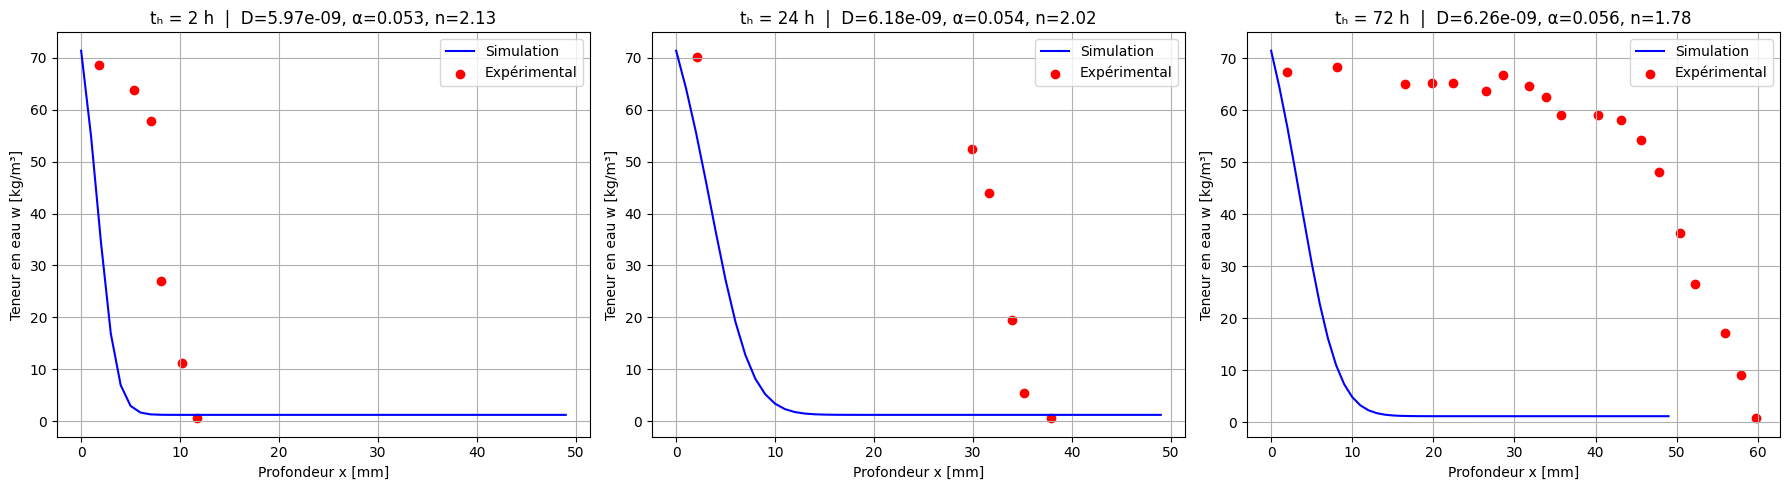

In [3]:
# === 11. Comparaison simulation vs. données expérimentales ===
import matplotlib.pyplot as plt

# liste des temps d'imprégnation à comparer
t_h_list = [2.0, 24.0, 72.0]

# créer 1 ligne de 3 graphiques
fig, axes = plt.subplots(1, len(t_h_list), figsize=(18, 5))

for ax, t_h in zip(axes, t_h_list):
    # 1) Extraire les données expérimentales
    df_t = df_all[df_all['t_h'] == t_h]
    phi, T, wc, S0 = df_t.iloc[0][['phi', 'T', 'w_c', 'S0']].values

    # 2) Préparer les tenseurs correcta pour la simulation
    inp = tf.constant([[phi, T, wc, S0, t_h]], dtype=tf.float32)
    # on force phi et rho_eau en float32 avant l'appel
    phi_tf    = tf.constant(phi, dtype=tf.float32)
    rho_eau_tf= tf.constant(1000.0, dtype=tf.float32)
    dx_tf     = tf.constant(1e-3, dtype=tf.float32)
    dt_tf     = tf.constant(30.0, dtype=tf.float32)
    Tmax_tf   = tf.constant(t_h * 3600.0, dtype=tf.float32)
    Nx_tf     = tf.constant(50, dtype=tf.int32)

    # 3) Prédire et simuler
    Dv_pred, alpha_pred, n_pred = extract_parameters_constrained(model(normalize(inp)))
    x_sim, w_sim = simulate_model_tf(
        Dv_pred, alpha_pred, n_pred,
        tf.constant(S0, dtype=tf.float32),
        phi_tf, rho_eau_tf,
        dx_tf, dt_tf, Tmax_tf, Nx_tf
    )

    # 4) Plot
    x_mm  = x_sim.numpy() * 1000
    w_mod = w_sim.numpy()
    ax.plot(x_mm, w_mod, 'b-', label='Simulation')
    ax.scatter(df_t['x_mm'], df_t['w_exp'], c='r', marker='o', label='Expérimental')
    ax.set_xlabel('Profondeur x [mm]')
    ax.set_ylabel('Teneur en eau w [kg/m³]')
    ax.set_title(f'tₕ = {int(t_h)} h  |  D={Dv_pred.numpy():.2e}, α={alpha_pred.numpy():.3f}, n={n_pred.numpy():.2f}')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()


In [12]:
# ⚙️ Physical simulation model (TensorFlow version)
@tf.function
def simulate_model_tf(Dv, S0, phi, rho_eau, dx, dt, Tmax, Nx):
    Nt = tf.cast(tf.math.round(Tmax / dt), tf.int32)
    x_vals = tf.linspace(0.0, dx * tf.cast(Nx - 1, tf.float32), Nx)
    alpha0 = 0.001; Sc = 0.8; nShape = 5
    K_in = 1.7e-20; eta_l = 1e-3; Pc0 = 5e6; beta = 2.5; S_cap = 0.9
    S = tf.ones((Nx,), dtype=tf.float32) * S0
    S = tf.tensor_scatter_nd_update(S, [[0]], [S0])
    M = tf.ones_like(S)
    M = tf.tensor_scatter_nd_update(M, [[0], [Nx-1]], [0.5, 0.5]) * dx

    def Dvapeur(S_val):
        fs = alpha0 + (1.0 - alpha0) / (1.0 + tf.pow((1.0 - S_val) / (1.0 - Sc), nShape))
        return tf.clip_by_value(fs, 0.0, 10.0) * Dv

    def Dcapi(S_val):
        dpc = -beta * Pc0 * tf.pow(S_val, -beta - 1)
        return tf.where(S_val < 1e-12, 0.0, tf.abs(dpc) * K_in / eta_l)

    def D_S(S_val):
        return tf.where(S_val >= S_cap, Dcapi(S_val), Dvapeur(S_val))

    def time_step(n, S_t):
        def picard_loop(i, S_old, S_next):
            D_vals = D_S(S_old)
            D_left = (D_vals[:-2] + D_vals[1:-1]) / 2
            D_right = (D_vals[1:-1] + D_vals[2:]) / 2
            diag = tf.concat([[1.0], 1/dt * M[1:-1] + (D_left + D_right) / dx**2, [1.0]], axis=0)
            lower = tf.concat([[0.0], -D_left / dx**2, [0.0]], axis=0)
            upper = tf.concat([[0.0], -D_right / dx**2, [0.0]], axis=0)
            A = tf.linalg.diag(diag) + tf.linalg.diag(lower[1:], k=-1) + tf.linalg.diag(upper[:-1], k=1)
            b = M / dt * S_t
            b = tf.tensor_scatter_nd_update(b, [[0], [Nx-1]], [S0, S_t[Nx-2]])
            S_candidate = tf.linalg.solve(A, tf.expand_dims(b, axis=1))[:, 0]
            err = tf.reduce_max(tf.abs(S_candidate - S_old))
            return tf.cond(err < 1e-5,
                           lambda: (20, S_candidate, S_candidate),
                           lambda: (i+1, S_candidate, S_next))

        _, S_out, _ = tf.while_loop(lambda i, *_: i < 20, picard_loop, [0, S_t, S_t])
        return n+1, S_out

    n0 = tf.constant(0)
    _, S_final = tf.while_loop(lambda n, *_: n < Nt, time_step, [n0, S])
    w_final = phi * rho_eau * S_final
    return x_vals, w_final